# Fixed Income Analytics & Interest Rate Risk

## Objective

This project develops a fixed-income analytics and interest-rate risk framework covering bond pricing, yield measures, duration, convexity, yield-curve shocks and portfolio-level sensitivity analysis.

The objective is to quantify how bond values respond to changes in interest rates and to compare analytical approximations with exact repricing under both parallel and non-parallel yield-curve scenarios.

### Core Components

- Bond pricing and yield to maturity
- Macaulay and modified duration
- Convexity
- Duration-convexity P&L approximation
- Yield-curve construction
- Parallel and non-parallel rate shocks
- Key-rate sensitivity
- Multi-bond portfolio aggregation
- Historical and hypothetical stress testing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import brentq
from scipy.interpolate import interp1d

pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.6f}"
)

## 1. Bond Pricing and the Price–Yield Relationship

A fixed-rate bond is valued as the present value of its coupon payments and principal repayment. The pricing function below assumes level coupon payments and a constant yield to maturity, with semiannual compounding by default.

The initial example also illustrates the inverse, nonlinear relationship between bond prices and yields: as required yield rises, the present value of the bond's fixed cash flows falls.


In [2]:
def bond_price(
    face_value,
    coupon_rate,
    maturity,
    yield_to_maturity,
    frequency=2
):
    periods = int(maturity * frequency)

    coupon = (
        face_value
        * coupon_rate
        / frequency
    )

    periodic_yield = (
        yield_to_maturity
        / frequency
    )

    cash_flows = np.full(
        periods,
        coupon,
        dtype=float
    )

    cash_flows[-1] += face_value

    discount_factors = (
        1
        / (
            1 + periodic_yield
        ) ** np.arange(
            1,
            periods + 1
        )
    )

    price = np.sum(
        cash_flows
        * discount_factors
    )

    return price

In [3]:
test_price = bond_price(
    face_value=1000,
    coupon_rate=0.04,
    maturity=5,
    yield_to_maturity=0.05,
    frequency=2
)

print(
    f"Bond price: ${test_price:,.2f}"
)

Bond price: $956.24


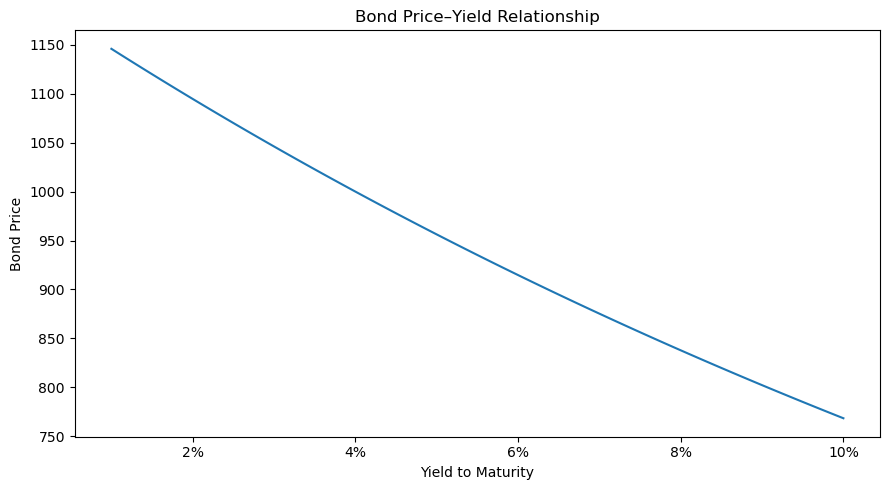

In [4]:
yields = np.linspace(
    0.01,
    0.10,
    100
)

prices = [
    bond_price(
        face_value=1000,
        coupon_rate=0.04,
        maturity=5,
        yield_to_maturity=y,
        frequency=2
    )
    for y in yields
]

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    yields,
    prices
)

ax.set_title(
    "Bond Price–Yield Relationship"
)

ax.set_xlabel(
    "Yield to Maturity"
)

ax.set_ylabel(
    "Bond Price"
)

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{x:.0%}"
    )
)

plt.tight_layout()
plt.show()

## 2. Yield to Maturity, Duration and Convexity

Bond price sensitivity to interest-rate movements is measured using duration and convexity.

- **Yield to Maturity (YTM)** is the discount rate that equates the present value of a bond's future cash flows to its observed market price.
- **Macaulay Duration** measures the weighted-average time to receipt of the bond's cash flows.
- **Modified Duration** approximates the percentage price change for a small change in yield.
- **Convexity** captures the curvature of the price-yield relationship and improves the accuracy of duration-based price approximations for larger yield changes.

In [5]:
def yield_to_maturity(
    market_price,
    face_value,
    coupon_rate,
    maturity,
    frequency=2
):
    def objective(y):
        return (
            bond_price(
                face_value=face_value,
                coupon_rate=coupon_rate,
                maturity=maturity,
                yield_to_maturity=y,
                frequency=frequency
            )
            - market_price
        )

    return brentq(
        objective,
        -0.99,
        1.00
    )

In [6]:
implied_ytm = yield_to_maturity(
    market_price=test_price,
    face_value=1000,
    coupon_rate=0.04,
    maturity=5,
    frequency=2
)

print(
    f"Implied YTM: {implied_ytm:.4%}"
)

Implied YTM: 5.0000%


In [7]:
def bond_duration(
    face_value,
    coupon_rate,
    maturity,
    yield_to_maturity,
    frequency=2
):
    periods = int(
        maturity * frequency
    )

    coupon = (
        face_value
        * coupon_rate
        / frequency
    )

    periodic_yield = (
        yield_to_maturity
        / frequency
    )

    times = (
        np.arange(
            1,
            periods + 1
        )
        / frequency
    )

    cash_flows = np.full(
        periods,
        coupon,
        dtype=float
    )

    cash_flows[-1] += face_value

    discount_factors = (
        1
        / (
            1 + periodic_yield
        ) ** np.arange(
            1,
            periods + 1
        )
    )

    present_values = (
        cash_flows
        * discount_factors
    )

    price = present_values.sum()

    macaulay_duration = (
        times
        @ present_values
        / price
    )

    modified_duration = (
        macaulay_duration
        / (
            1
            + yield_to_maturity
            / frequency
        )
    )

    return (
        macaulay_duration,
        modified_duration
    )

In [8]:
macaulay_duration, modified_duration = (
    bond_duration(
        face_value=1000,
        coupon_rate=0.04,
        maturity=5,
        yield_to_maturity=0.05,
        frequency=2
    )
)

print(
    f"Macaulay Duration: "
    f"{macaulay_duration:.4f} years"
)

print(
    f"Modified Duration: "
    f"{modified_duration:.4f}"
)

Macaulay Duration: 4.5695 years
Modified Duration: 4.4581


In [9]:
def bond_convexity(
    face_value,
    coupon_rate,
    maturity,
    yield_to_maturity,
    frequency=2
):
    periods = int(
        maturity * frequency
    )

    coupon = (
        face_value
        * coupon_rate
        / frequency
    )

    periodic_yield = (
        yield_to_maturity
        / frequency
    )

    cash_flows = np.full(
        periods,
        coupon,
        dtype=float
    )

    cash_flows[-1] += face_value

    k = np.arange(
        1,
        periods + 1
    )

    discount_factors = (
        1
        / (
            1 + periodic_yield
        ) ** k
    )

    price = np.sum(
        cash_flows
        * discount_factors
    )

    convexity = (
        np.sum(
            cash_flows
            * k
            * (k + 1)
            / (
                1 + periodic_yield
            ) ** (k + 2)
        )
        / (
            price
            * frequency ** 2
        )
    )

    return convexity

In [10]:
convexity = bond_convexity(
    face_value=1000,
    coupon_rate=0.04,
    maturity=5,
    yield_to_maturity=0.05,
    frequency=2
)

print(
    f"Convexity: {convexity:.4f}"
)

Convexity: 23.1944


## 3. Interest-Rate Shock Analysis

Modified duration provides a first-order approximation of bond price sensitivity to changes in yield:

$$
\frac{\Delta P}{P}
\approx
-D_{mod}\Delta y
$$

Convexity adds a second-order adjustment:

$$
\frac{\Delta P}{P}
\approx
-D_{mod}\Delta y
+
\frac{1}{2}C(\Delta y)^2
$$

The accuracy of these approximations is compared with exact bond repricing across a range of parallel yield shocks.

In [11]:
rate_shocks_bps = [
    -200,
    -100,
    -50,
    -25,
    25,
    50,
    100,
    200
]

base_yield = 0.05
base_price = test_price

shock_results = []

for shock_bps in rate_shocks_bps:

    delta_y = shock_bps / 10_000

    shocked_yield = (
        base_yield
        + delta_y
    )

    exact_price = bond_price(
        face_value=1000,
        coupon_rate=0.04,
        maturity=5,
        yield_to_maturity=shocked_yield,
        frequency=2
    )

    exact_return = (
        exact_price / base_price
        - 1
    )

    duration_return = (
        -modified_duration
        * delta_y
    )

    duration_convexity_return = (
        -modified_duration
        * delta_y
        + 0.5
        * convexity
        * delta_y ** 2
    )

    shock_results.append({
        "Shock (bp)": shock_bps,
        "Yield": shocked_yield,
        "Exact Price": exact_price,
        "Exact Return": exact_return,
        "Duration Approx": duration_return,
        "Duration + Convexity": duration_convexity_return
    })

shock_table = pd.DataFrame(
    shock_results
)

shock_table

,Shock (bp),Yield,Exact Price,Exact Return,Duration Approx,Duration + Convexity
0,-200,0.030000,"1,046.110923",0.093984,0.089161,0.093800
1,-100,0.040000,"1,000.000000",0.045763,0.044581,0.045740
2,-50,0.045000,977.834459,0.022583,0.022290,0.022580
3,-25,0.047500,966.966751,0.011218,0.011145,0.011218
4,25,0.052500,945.651234,-0.011073,-0.011145,-0.011073
5,50,0.055000,935.199429,-0.022003,-0.022290,-0.022000
6,100,0.060000,914.697972,-0.043443,-0.044581,-0.043421
7,200,0.070000,875.250920,-0.084695,-0.089161,-0.084522


In [12]:
shock_table["Duration Error"] = (
    shock_table["Duration Approx"]
    - shock_table["Exact Return"]
)

shock_table["Duration + Convexity Error"] = (
    shock_table["Duration + Convexity"]
    - shock_table["Exact Return"]
)

shock_table

,Shock (bp),Yield,Exact Price,Exact Return,Duration Approx,Duration + Convexity,Duration Error,Duration + Convexity Error
0,-200,0.030000,"1,046.110923",0.093984,0.089161,0.093800,-0.004823,-0.000184
1,-100,0.040000,"1,000.000000",0.045763,0.044581,0.045740,-0.001182,-0.000023
2,-50,0.045000,977.834459,0.022583,0.022290,0.022580,-0.000293,-0.000003
3,-25,0.047500,966.966751,0.011218,0.011145,0.011218,-0.000073,-0.000000
4,25,0.052500,945.651234,-0.011073,-0.011145,-0.011073,-0.000072,0.000000
5,50,0.055000,935.199429,-0.022003,-0.022290,-0.022000,-0.000287,0.000003
6,100,0.060000,914.697972,-0.043443,-0.044581,-0.043421,-0.001138,0.000022
7,200,0.070000,875.250920,-0.084695,-0.089161,-0.084522,-0.004466,0.000173


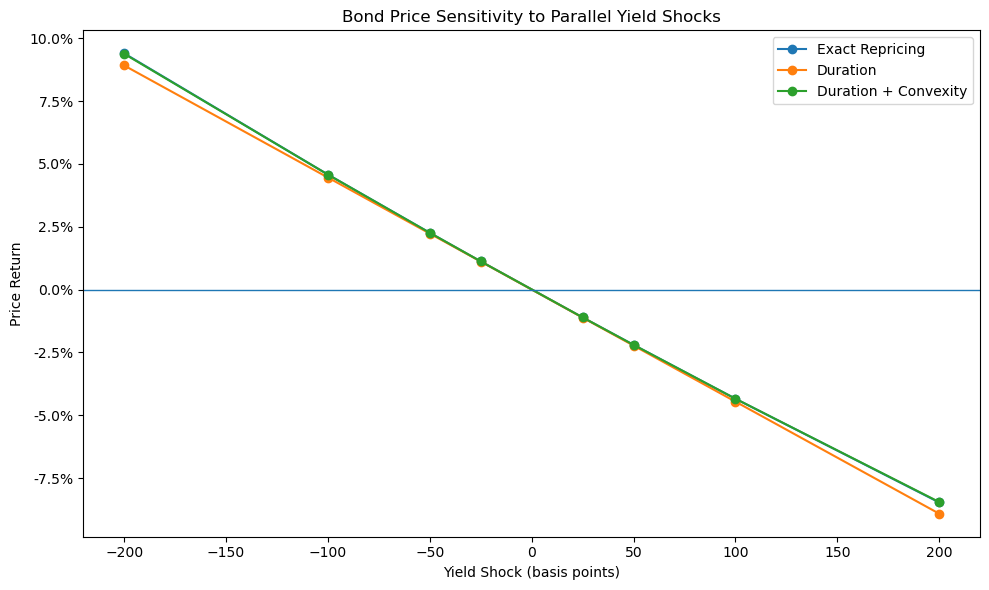

In [13]:
fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.plot(
    shock_table["Shock (bp)"],
    shock_table["Exact Return"],
    marker="o",
    label="Exact Repricing"
)

ax.plot(
    shock_table["Shock (bp)"],
    shock_table["Duration Approx"],
    marker="o",
    label="Duration"
)

ax.plot(
    shock_table["Shock (bp)"],
    shock_table["Duration + Convexity"],
    marker="o",
    label="Duration + Convexity"
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_title(
    "Bond Price Sensitivity to Parallel Yield Shocks"
)

ax.set_xlabel(
    "Yield Shock (basis points)"
)

ax.set_ylabel(
    "Price Return"
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{x:.1%}"
    )
)

ax.legend()

plt.tight_layout()
plt.show()

### Interpretation

The results illustrate the limitations of using duration as a purely linear approximation of bond price sensitivity.

For small yield changes, modified duration closely approximates the exact repricing result. However, approximation error increases as the magnitude of the interest-rate shock grows because the true price-yield relationship is convex rather than linear.

For a +200 bp yield shock, exact repricing produces a loss of approximately 8.47%, while the duration-only approximation implies a loss of approximately 8.92%. Incorporating convexity reduces the approximation error substantially, producing an estimated loss of approximately 8.45%.

Positive convexity also creates asymmetric price responses. A 200 bp decline in yield increases the bond price by approximately 9.40%, whereas a 200 bp increase reduces the price by approximately 8.47%.

Duration therefore provides an effective first-order measure of interest-rate exposure, while convexity becomes increasingly important for larger yield movements.

## 4. Yield Curve Construction

A single yield-to-maturity measure assumes that all of a bond's cash flows are discounted using the same rate. In practice, interest rates vary across maturities, producing a term structure of interest rates.

An illustrative yield curve is constructed across several maturity points and interpolated to obtain rates between the observed tenors. This allows bonds with different maturities to be valued against a common term structure and provides the foundation for non-parallel yield-curve stress testing.

In [14]:
curve_data = pd.DataFrame({
    "Maturity": [
        0.5,
        1,
        2,
        3,
        5,
        7,
        10,
        20,
        30
    ],
    "Yield": [
        0.0430,
        0.0415,
        0.0400,
        0.0395,
        0.0405,
        0.0415,
        0.0430,
        0.0450,
        0.0460
    ]
})

curve_data

,Maturity,Yield
0,0.500000,0.043000
1,1.000000,0.041500
2,2.000000,0.040000
3,3.000000,0.039500
4,5.000000,0.040500
5,7.000000,0.041500
6,10.000000,0.043000
7,20.000000,0.045000
8,30.000000,0.046000


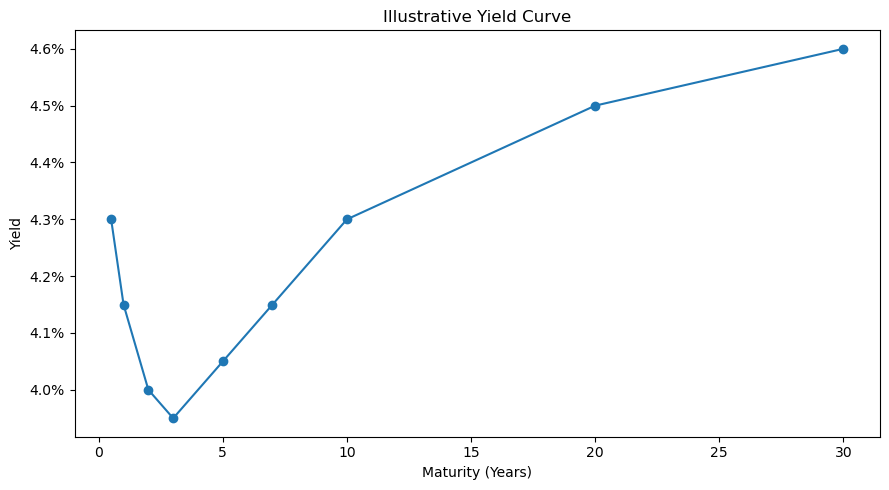

In [15]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    curve_data["Maturity"],
    curve_data["Yield"],
    marker="o"
)

ax.set_title(
    "Illustrative Yield Curve"
)

ax.set_xlabel(
    "Maturity (Years)"
)

ax.set_ylabel(
    "Yield"
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{x:.1%}"
    )
)

plt.tight_layout()
plt.show()

In [16]:
yield_curve = interp1d(
    curve_data["Maturity"],
    curve_data["Yield"],
    kind="linear",
    bounds_error=False,
    fill_value="extrapolate"
)

curve_maturities = np.linspace(
    0.5,
    30,
    200
)

interpolated_yields = yield_curve(
    curve_maturities
)

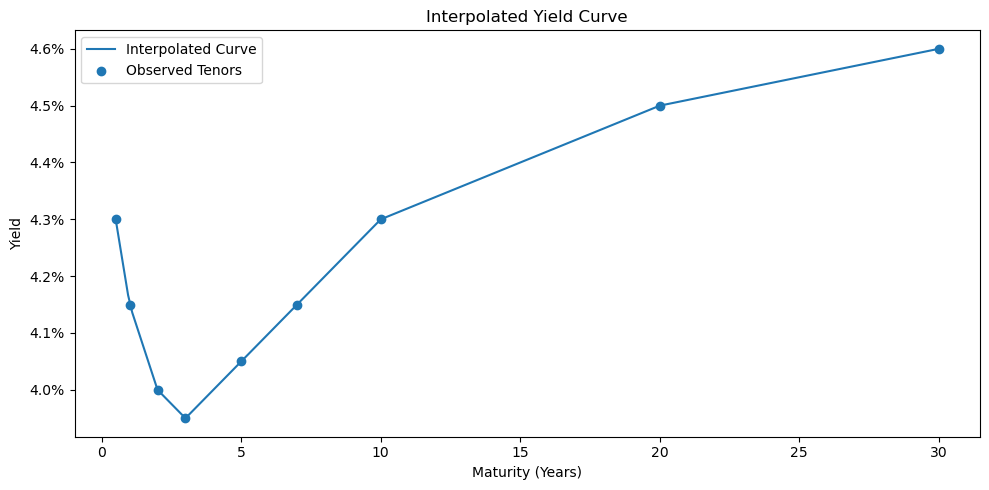

In [17]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    curve_maturities,
    interpolated_yields,
    label="Interpolated Curve"
)

ax.scatter(
    curve_data["Maturity"],
    curve_data["Yield"],
    label="Observed Tenors"
)

ax.set_title(
    "Interpolated Yield Curve"
)

ax.set_xlabel(
    "Maturity (Years)"
)

ax.set_ylabel(
    "Yield"
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{x:.1%}"
    )
)

ax.legend()

plt.tight_layout()
plt.show()

## 5. Term-Structure Bond Pricing

Yield to maturity summarizes a bond's cash flows using a single discount rate. A term-structure framework instead discounts each cash flow using a maturity-specific rate.

For this section, the interpolated curve is treated as an illustrative spot-rate curve for valuation purposes. Each coupon and principal payment is discounted using the interpolated rate corresponding to its payment date.

This provides a more realistic foundation for analysing non-parallel yield-curve movements and portfolio-level interest-rate risk.

In [18]:
def bond_price_spot_curve(
    face_value,
    coupon_rate,
    maturity,
    spot_curve,
    frequency=2
):
    periods = int(
        maturity * frequency
    )

    coupon = (
        face_value
        * coupon_rate
        / frequency
    )

    payment_times = (
        np.arange(
            1,
            periods + 1
        )
        / frequency
    )

    cash_flows = np.full(
        periods,
        coupon,
        dtype=float
    )

    cash_flows[-1] += face_value

    spot_rates = spot_curve(
        payment_times
    )

    discount_factors = (
        1
        / (
            1
            + spot_rates / frequency
        ) ** (
            payment_times * frequency
        )
    )

    price = np.sum(
        cash_flows
        * discount_factors
    )

    return price

In [19]:
bond_portfolio = pd.DataFrame({
    "Bond": [
        "2Y Note",
        "5Y Note",
        "10Y Note",
        "20Y Bond"
    ],
    "Face Value": [
        1_000_000,
        1_000_000,
        1_000_000,
        1_000_000
    ],
    "Coupon Rate": [
        0.035,
        0.040,
        0.045,
        0.050
    ],
    "Maturity": [
        2,
        5,
        10,
        20
    ]
})

bond_portfolio

,Bond,Face Value,Coupon Rate,Maturity
0,2Y Note,1000000,0.035000,2
1,5Y Note,1000000,0.040000,5
2,10Y Note,1000000,0.045000,10
3,20Y Bond,1000000,0.050000,20


In [20]:
bond_portfolio["Price"] = bond_portfolio.apply(
    lambda row: bond_price_spot_curve(
        face_value=row["Face Value"],
        coupon_rate=row["Coupon Rate"],
        maturity=row["Maturity"],
        spot_curve=yield_curve,
        frequency=2
    ),
    axis=1
)

bond_portfolio["Market Value"] = (
    bond_portfolio["Price"]
)

bond_portfolio

,Bond,Face Value,Coupon Rate,Maturity,Price,Market Value
0,2Y Note,1000000,0.035000,2,"990,412.601075","990,412.601075"
1,5Y Note,1000000,0.040000,5,"997,907.828529","997,907.828529"
2,10Y Note,1000000,0.045000,10,"1,018,864.072052","1,018,864.072052"
3,20Y Bond,1000000,0.050000,20,"1,075,799.813285","1,075,799.813285"


In [21]:
portfolio_market_value = (
    bond_portfolio["Market Value"]
    .sum()
)

bond_portfolio["Portfolio Weight"] = (
    bond_portfolio["Market Value"]
    / portfolio_market_value
)

print(
    f"Total Portfolio Market Value: "
    f"${portfolio_market_value:,.2f}"
)

bond_portfolio

Total Portfolio Market Value: $4,082,984.31


,Bond,Face Value,Coupon Rate,Maturity,Price,Market Value,Portfolio Weight
0,2Y Note,1000000,0.035000,2,"990,412.601075","990,412.601075",0.242571
1,5Y Note,1000000,0.040000,5,"997,907.828529","997,907.828529",0.244406
2,10Y Note,1000000,0.045000,10,"1,018,864.072052","1,018,864.072052",0.249539
3,20Y Bond,1000000,0.050000,20,"1,075,799.813285","1,075,799.813285",0.263484


In [22]:
bond_portfolio["Yield"] = (
    bond_portfolio["Maturity"]
    .apply(
        lambda x: float(
            yield_curve(x)
        )
    )
)

In [23]:
duration_results = bond_portfolio.apply(
    lambda row: bond_duration(
        face_value=row["Face Value"],
        coupon_rate=row["Coupon Rate"],
        maturity=row["Maturity"],
        yield_to_maturity=row["Yield"],
        frequency=2
    ),
    axis=1
)

bond_portfolio[
    "Macaulay Duration"
] = [
    result[0]
    for result in duration_results
]

bond_portfolio[
    "Modified Duration"
] = [
    result[1]
    for result in duration_results
]

bond_portfolio["Convexity"] = (
    bond_portfolio.apply(
        lambda row: bond_convexity(
            face_value=row["Face Value"],
            coupon_rate=row["Coupon Rate"],
            maturity=row["Maturity"],
            yield_to_maturity=row["Yield"],
            frequency=2
        ),
        axis=1
    )
)

In [24]:
portfolio_duration = (
    bond_portfolio[
        "Portfolio Weight"
    ]
    * bond_portfolio[
        "Modified Duration"
    ]
).sum()

portfolio_convexity = (
    bond_portfolio[
        "Portfolio Weight"
    ]
    * bond_portfolio[
        "Convexity"
    ]
).sum()

print(
    f"Portfolio Modified Duration: "
    f"{portfolio_duration:.4f}"
)

print(
    f"Portfolio Convexity: "
    f"{portfolio_convexity:.4f}"
)

bond_portfolio

Portfolio Modified Duration: 6.9366
Portfolio Convexity: 83.3964


,Bond,Face Value,Coupon Rate,Maturity,Price,Market Value,Portfolio Weight,Yield,Macaulay Duration,Modified Duration,Convexity
0,2Y Note,1000000,0.035000,2,"990,412.601075","990,412.601075",0.242571,0.040000,1.948711,1.910501,4.641788
1,5Y Note,1000000,0.040000,5,"997,907.828529","997,907.828529",0.244406,0.040500,4.580544,4.489629,23.483566
2,10Y Note,1000000,0.045000,10,"1,018,864.072052","1,018,864.072052",0.249539,0.043000,8.178965,8.006819,76.572634
3,20Y Bond,1000000,0.050000,20,"1,075,799.813285","1,075,799.813285",0.263484,0.045000,13.108439,12.819989,217.937885


### Portfolio Risk Profile

The portfolio has a market value of approximately $4.08 million and a modified duration of 6.94. For a small parallel shift in yields, this implies that a 100 bp increase in rates would produce an approximate 6.94% decline in portfolio value before accounting for convexity.

Interest-rate sensitivity is concentrated disproportionately in the longer-maturity securities. The 20-year bond represents approximately one quarter of portfolio market value but has a modified duration of 12.82 and substantially greater convexity than the shorter-maturity positions.

This demonstrates an important distinction between capital allocation and risk allocation: similar market-value weights do not imply similar contributions to interest-rate risk.

## 8. Yield-Curve Scenario Analysis

Fixed-income portfolios are exposed not only to changes in the overall level of interest rates but also to changes in the shape of the yield curve.

Four hypothetical scenarios are considered:

- **Parallel +100 bp:** all maturities increase by 100 bp.
- **Parallel -100 bp:** all maturities decrease by 100 bp.
- **Bear Steepener:** long-term yields rise more than short-term yields.
- **Bear Flattener:** short-term yields rise more than long-term yields.

Each scenario is applied directly to the term structure and every bond is repriced using its shocked maturity-specific discount rates. Exact repricing therefore captures both the magnitude and location of the portfolio's yield-curve exposure.

In [25]:
scenario_shocks = {
    "Parallel +100 bp": np.array([
        100, 100, 100, 100, 100,
        100, 100, 100, 100
    ]),

    "Parallel -100 bp": np.array([
        -100, -100, -100, -100, -100,
        -100, -100, -100, -100
    ]),

    "Bear Steepener": np.array([
        25, 30, 40, 50, 65,
        80, 100, 125, 150
    ]),

    "Bear Flattener": np.array([
        150, 140, 125, 110, 90,
        75, 60, 40, 25
    ])
}

In [26]:
scenario_curves = {}

for scenario, shocks_bps in scenario_shocks.items():

    shocked_yields = (
        curve_data["Yield"].values
        + shocks_bps / 10_000
    )

    scenario_curves[scenario] = interp1d(
        curve_data["Maturity"],
        shocked_yields,
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )

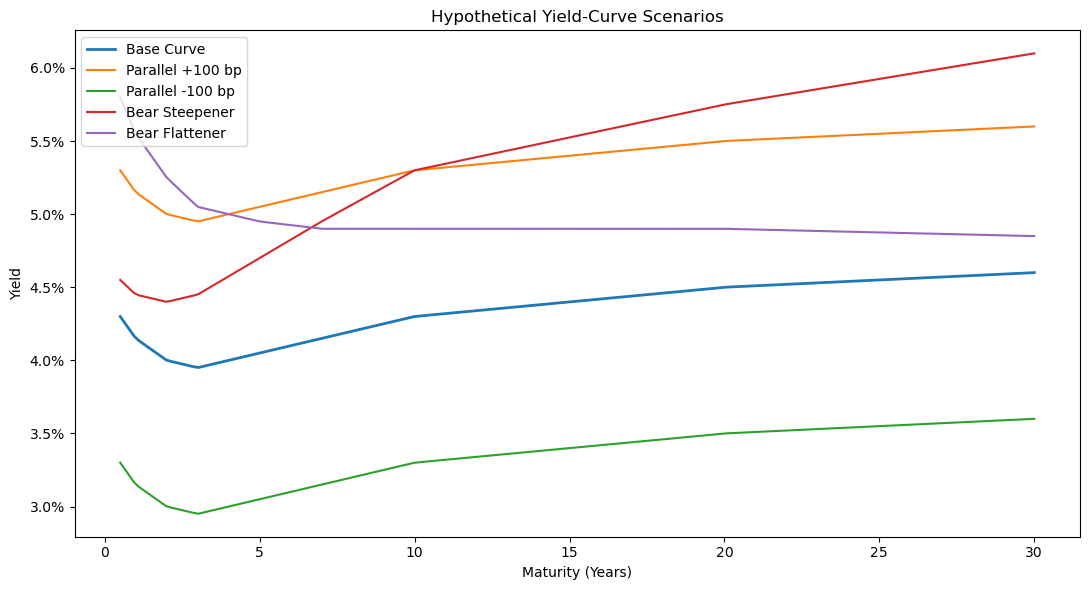

In [27]:
fig, ax = plt.subplots(
    figsize=(11, 6)
)

ax.plot(
    curve_maturities,
    yield_curve(curve_maturities),
    linewidth=2,
    label="Base Curve"
)

for scenario, curve in scenario_curves.items():

    ax.plot(
        curve_maturities,
        curve(curve_maturities),
        label=scenario
    )

ax.set_title(
    "Hypothetical Yield-Curve Scenarios"
)

ax.set_xlabel(
    "Maturity (Years)"
)

ax.set_ylabel(
    "Yield"
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{x:.1%}"
    )
)

ax.legend()

plt.tight_layout()
plt.show()

In [28]:
scenario_results = []

for scenario, shocked_curve in scenario_curves.items():

    scenario_value = 0

    for _, bond in bond_portfolio.iterrows():

        shocked_price = bond_price_spot_curve(
            face_value=bond["Face Value"],
            coupon_rate=bond["Coupon Rate"],
            maturity=bond["Maturity"],
            spot_curve=shocked_curve,
            frequency=2
        )

        scenario_value += shocked_price

    pnl = (
        scenario_value
        - portfolio_market_value
    )

    return_pct = (
        pnl
        / portfolio_market_value
    )

    scenario_results.append({
        "Scenario": scenario,
        "Portfolio Value": scenario_value,
        "P&L ($)": pnl,
        "Return": return_pct
    })

curve_scenario_results = pd.DataFrame(
    scenario_results
)

curve_scenario_results

,Scenario,Portfolio Value,P&L ($),Return
0,Parallel +100 bp,"3,816,355.274731","-266,629.040211",-0.065302
1,Parallel -100 bp,"4,383,612.235551","300,627.920610",0.073629
2,Bear Steepener,"3,831,443.857071","-251,540.457871",-0.061607
3,Bear Flattener,"3,903,877.137792","-179,107.177149",-0.043867


In [29]:
bond_scenario_pnl = []

for scenario, shocked_curve in scenario_curves.items():

    row = {
        "Scenario": scenario
    }

    total_pnl = 0

    for _, bond in bond_portfolio.iterrows():

        shocked_price = bond_price_spot_curve(
            face_value=bond["Face Value"],
            coupon_rate=bond["Coupon Rate"],
            maturity=bond["Maturity"],
            spot_curve=shocked_curve,
            frequency=2
        )

        pnl = (
            shocked_price
            - bond["Market Value"]
        )

        row[f"{bond['Bond']} P&L"] = pnl

        total_pnl += pnl

    row["Total P&L"] = total_pnl

    bond_scenario_pnl.append(row)

bond_scenario_pnl = pd.DataFrame(
    bond_scenario_pnl
)

bond_scenario_pnl

,Scenario,2Y Note P&L,5Y Note P&L,10Y Note P&L,20Y Bond P&L,Total P&L
0,Parallel +100 bp,"-18,694.528120","-43,652.875959","-77,744.912089","-126,536.724042","-266,629.040211"
1,Parallel -100 bp,"19,154.307193","45,996.983211","85,543.094875","149,933.535330","300,627.920610"
2,Bear Steepener,"-7,491.305905","-28,051.642098","-73,688.170581","-142,309.339287","-251,540.457871"
3,Bear Flattener,"-23,360.482615","-40,182.577996","-51,247.368465","-64,316.748073","-179,107.177149"


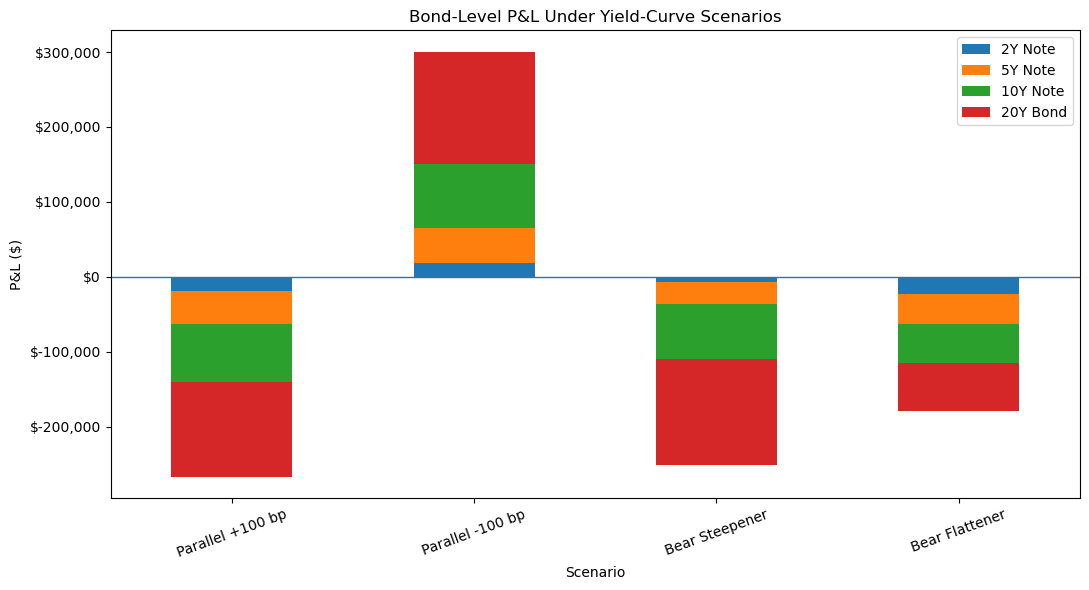

In [30]:
pnl_plot = (
    bond_scenario_pnl
    .set_index("Scenario")
    .drop(columns="Total P&L")
)

pnl_plot.columns = [
    col.replace(" P&L", "")
    for col in pnl_plot.columns
]

ax = pnl_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_title(
    "Bond-Level P&L Under Yield-Curve Scenarios"
)

ax.set_xlabel(
    "Scenario"
)

ax.set_ylabel(
    "P&L ($)"
)

ax.tick_params(
    axis="x",
    rotation=20
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"${x:,.0f}"
    )
)

plt.tight_layout()
plt.show()

### Scenario Analysis Interpretation

The scenario analysis demonstrates that portfolio interest-rate risk depends on both the overall level and the shape of the yield curve.

A parallel 100 bp increase in yields reduces portfolio value by approximately $266,629, or 6.53%, while a parallel 100 bp decline increases value by approximately $300,628, or 7.36%. The asymmetric response reflects the positive convexity of the bond portfolio.

The non-parallel scenarios reveal risks that cannot be captured by aggregate duration alone. Under the bear steepener, losses are concentrated at the long end of the portfolio, with the 20-year bond contributing approximately $142,309 of the $251,540 total loss. Under the bear flattener, the shock is concentrated more heavily at shorter maturities and the total portfolio loss falls to approximately $179,107.

These results demonstrate that portfolio duration is useful for measuring exposure to small parallel rate movements, but it does not identify where along the yield curve the underlying interest-rate risk is concentrated. Maturity-specific sensitivity measures are therefore required to assess non-parallel curve risk.

## 9. Key-Rate Duration

Aggregate duration measures sensitivity to a parallel shift in the yield curve but does not identify where along the term structure that exposure is concentrated.

Key-rate duration addresses this limitation by applying a small localized shock around individual maturity points while leaving distant parts of the curve relatively unchanged.

For each key maturity, the portfolio is repriced following a +1 bp localized shift. The resulting change in portfolio value is used to estimate the corresponding key-rate duration.

The sum of key-rate exposures provides an approximate decomposition of the portfolio's overall interest-rate sensitivity across the yield curve.

In [31]:
key_maturities = np.array([
    2,
    5,
    10,
    20
])

In [32]:
def key_rate_shock(
    maturities,
    key_maturity,
    shock_bps=1
):
    distances = np.abs(
        maturities - key_maturity
    )

    shock_width = {
        2: 2,
        5: 3,
        10: 5,
        20: 10
    }[key_maturity]

    weights = np.maximum(
        1 - distances / shock_width,
        0
    )

    return (
        weights
        * shock_bps
        / 10_000
    )

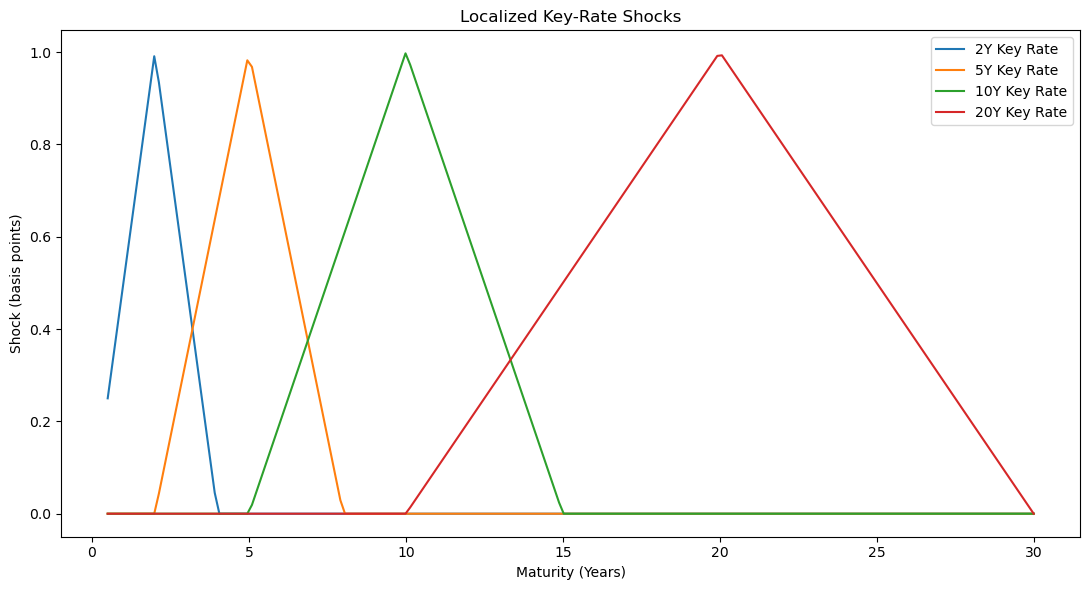

In [33]:
fig, ax = plt.subplots(
    figsize=(11, 6)
)

for key_maturity in key_maturities:

    shock = key_rate_shock(
        curve_maturities,
        key_maturity,
        shock_bps=1
    )

    ax.plot(
        curve_maturities,
        shock * 10_000,
        label=f"{key_maturity}Y Key Rate"
    )

ax.set_title(
    "Localized Key-Rate Shocks"
)

ax.set_xlabel(
    "Maturity (Years)"
)

ax.set_ylabel(
    "Shock (basis points)"
)

ax.legend()

plt.tight_layout()
plt.show()

In [34]:
key_rate_results = []

for key_maturity in key_maturities:

    node_shock = key_rate_shock(
        curve_data["Maturity"].values,
        key_maturity,
        shock_bps=1
    )

    shocked_node_yields = (
        curve_data["Yield"].values
        + node_shock
    )

    shocked_curve = interp1d(
        curve_data["Maturity"],
        shocked_node_yields,
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )

    shocked_portfolio_value = 0

    for _, bond in bond_portfolio.iterrows():

        shocked_price = bond_price_spot_curve(
            face_value=bond["Face Value"],
            coupon_rate=bond["Coupon Rate"],
            maturity=bond["Maturity"],
            spot_curve=shocked_curve,
            frequency=2
        )

        shocked_portfolio_value += shocked_price

    pnl = (
        shocked_portfolio_value
        - portfolio_market_value
    )

    key_rate_duration = (
        -pnl
        / portfolio_market_value
        / 0.0001
    )

    key_rate_results.append({
        "Key Maturity": key_maturity,
        "Shocked Portfolio Value": shocked_portfolio_value,
        "P&L for +1 bp": pnl,
        "Key-Rate Duration": key_rate_duration
    })

key_rate_table = pd.DataFrame(
    key_rate_results
)

key_rate_table

,Key Maturity,Shocked Portfolio Value,P&L for +1 bp,Key-Rate Duration
0,2,"4,082,737.559557",-246.755385,0.604351
1,5,"4,082,428.134277",-556.180665,1.362192
2,10,"4,082,020.965977",-963.348965,2.359424
3,20,"4,081,977.849773","-1,006.465169",2.465023


In [35]:
print(
    "Sum of Key-Rate Durations:",
    f"{key_rate_table['Key-Rate Duration'].sum():.4f}"
)

print(
    "Portfolio Modified Duration:",
    f"{portfolio_duration:.4f}"
)

Sum of Key-Rate Durations: 6.7910
Portfolio Modified Duration: 6.9366


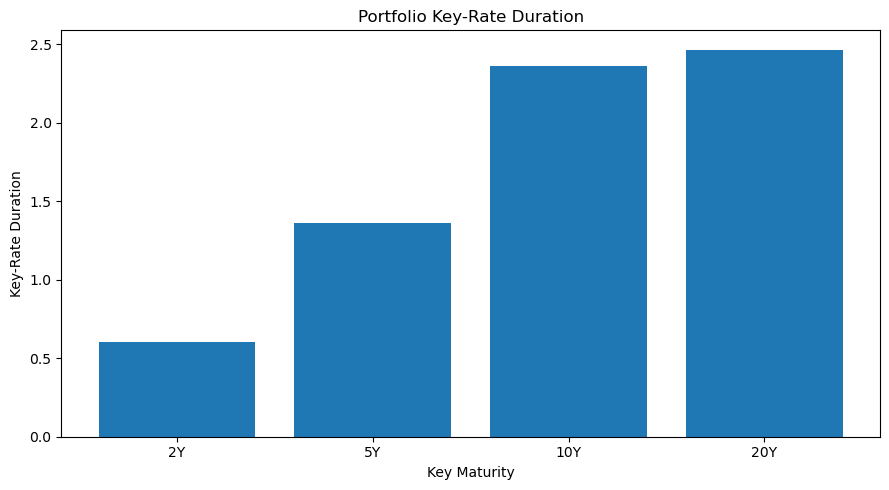

In [36]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.bar(
    key_rate_table["Key Maturity"].astype(str) + "Y",
    key_rate_table["Key-Rate Duration"]
)

ax.set_title(
    "Portfolio Key-Rate Duration"
)

ax.set_xlabel(
    "Key Maturity"
)

ax.set_ylabel(
    "Key-Rate Duration"
)

plt.tight_layout()
plt.show()

### Key-Rate Duration Interpretation

The key-rate analysis shows that the portfolio's interest-rate exposure is concentrated primarily at the intermediate and long end of the yield curve.

Estimated key-rate durations are approximately 0.60 at 2 years, 1.36 at 5 years, 2.36 at 10 years and 2.47 at 20 years. The 10-year and 20-year key rates therefore account for the majority of the portfolio's measured curve sensitivity.

The sum of key-rate durations is approximately 6.79, compared with an aggregate modified duration of 6.94. The values are reasonably close but are not expected to match exactly because the key-rate framework applies localized shocks to an interpolated term structure, whereas the earlier duration calculation uses maturity-specific yield-to-maturity approximations.

The decomposition provides information that aggregate duration cannot: it identifies where along the yield curve the portfolio is most exposed. This helps explain why long-end shocks such as the bear-steepening scenario generated disproportionately large losses in the 20-year position.


## 10. DV01 and Dollar Duration

Duration can be translated into monetary interest-rate exposure using DV01 (Dollar Value of One Basis Point).

DV01 estimates the change in market value associated with a one-basis-point increase in yield:

$$
DV01 \approx D_{mod} \times V \times 0.0001
$$

where:

- $D_{mod}$ is modified duration,
- $V$ is market value,
- and one basis point equals 0.0001.

DV01 provides an intuitive dollar measure of interest-rate sensitivity and can be calculated at both the individual-bond and portfolio level.

In [37]:
bond_portfolio["DV01"] = (
    bond_portfolio["Modified Duration"]
    * bond_portfolio["Market Value"]
    * 0.0001
)

bond_portfolio[
    [
        "Bond",
        "Market Value",
        "Modified Duration",
        "DV01"
    ]
]

,Bond,Market Value,Modified Duration,DV01
0,2Y Note,"990,412.601075",1.910501,189.218395
1,5Y Note,"997,907.828529",4.489629,448.023594
2,10Y Note,"1,018,864.072052",8.006819,815.785988
3,20Y Bond,"1,075,799.813285",12.819989,"1,379.174226"


In [38]:
portfolio_dv01 = (
    bond_portfolio["DV01"]
    .sum()
)

print(
    f"Portfolio DV01: "
    f"${portfolio_dv01:,.2f}"
)

Portfolio DV01: $2,832.20


In [39]:
parallel_1bp_curve = interp1d(
    curve_data["Maturity"],
    curve_data["Yield"] + 0.0001,
    kind="linear",
    bounds_error=False,
    fill_value="extrapolate"
)

parallel_1bp_value = 0

for _, bond in bond_portfolio.iterrows():

    parallel_1bp_value += (
        bond_price_spot_curve(
            face_value=bond["Face Value"],
            coupon_rate=bond["Coupon Rate"],
            maturity=bond["Maturity"],
            spot_curve=parallel_1bp_curve,
            frequency=2
        )
    )

exact_parallel_dv01 = (
    portfolio_market_value
    - parallel_1bp_value
)

print(
    f"Duration-based DV01: "
    f"${portfolio_dv01:,.2f}"
)

print(
    f"Exact repricing DV01: "
    f"${exact_parallel_dv01:,.2f}"
)

print(
    f"Difference: "
    f"${portfolio_dv01 - exact_parallel_dv01:,.2f}"
)

Duration-based DV01: $2,832.20
Exact repricing DV01: $2,825.66
Difference: $6.54


In [40]:
bond_portfolio[
    "DV01 Contribution"
] = (
    bond_portfolio["DV01"]
    / portfolio_dv01
)

dv01_table = bond_portfolio[
    [
        "Bond",
        "Market Value",
        "Portfolio Weight",
        "Modified Duration",
        "DV01",
        "DV01 Contribution"
    ]
].copy()

dv01_table

,Bond,Market Value,Portfolio Weight,Modified Duration,DV01,DV01 Contribution
0,2Y Note,"990,412.601075",0.242571,1.910501,189.218395,0.066810
1,5Y Note,"997,907.828529",0.244406,4.489629,448.023594,0.158189
2,10Y Note,"1,018,864.072052",0.249539,8.006819,815.785988,0.288039
3,20Y Bond,"1,075,799.813285",0.263484,12.819989,"1,379.174226",0.486962


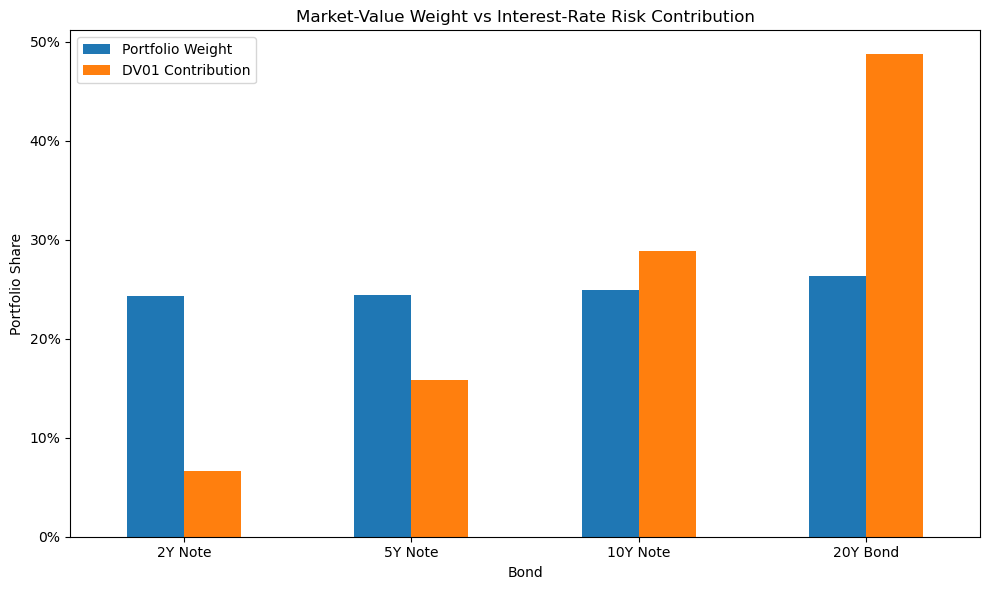

In [41]:
comparison = (
    dv01_table[
        [
            "Bond",
            "Portfolio Weight",
            "DV01 Contribution"
        ]
    ]
    .set_index("Bond")
)

ax = comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title(
    "Market-Value Weight vs Interest-Rate Risk Contribution"
)

ax.set_xlabel(
    "Bond"
)

ax.set_ylabel(
    "Portfolio Share"
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{x:.0%}"
    )
)

ax.tick_params(
    axis="x",
    rotation=0
)

plt.tight_layout()
plt.show()

### DV01 Interpretation

The portfolio has an estimated DV01 of approximately $2,832, meaning that a 1 bp parallel increase in yields produces an approximate $2,832 decline in market value.

Exact repricing under a +1 bp parallel curve shift produces a loss of approximately $2,826, only about $7 different from the duration-based estimate. This confirms that DV01 provides a highly accurate local approximation for very small rate movements.

The distribution of dollar interest-rate risk differs materially from the distribution of market value. The 20-year bond represents approximately 26% of portfolio value but contributes almost 49% of total DV01. By contrast, the 2-year position represents about 24% of capital but only around 7% of rate risk.

This illustrates that capital allocation and risk allocation can differ substantially in fixed-income portfolios, particularly when maturities vary widely.

## 11. Duration Hedging

Interest-rate exposure can be reduced by taking an offsetting position in another fixed-income instrument.

A simple duration hedge targets portfolio DV01. If the portfolio has positive DV01, a short position in a hedging bond can be sized so that the hedge DV01 offsets the portfolio's exposure.

The hedge ratio is:

$$
H = \frac{DV01_{portfolio}}{DV01_{hedge\ instrument}}
$$

The effectiveness of the hedge is then tested under both parallel and non-parallel yield-curve shocks.

In [42]:
hedge_bond = bond_portfolio.loc[
    bond_portfolio["Bond"] == "10Y Note"
].iloc[0]

hedge_unit_dv01 = (
    hedge_bond["DV01"]
    / hedge_bond["Face Value"]
)

single_10y_hedge_notional = (
    portfolio_dv01
    / hedge_unit_dv01
)

print(
    f"Hedge Notional: "
    f"${single_10y_hedge_notional:,.2f}"
)

Hedge Notional: $3,471,746.57


In [43]:
hedged_results = []

for scenario, shocked_curve in scenario_curves.items():

    # Reprice original portfolio
    shocked_portfolio_value = 0

    for _, bond in bond_portfolio.iterrows():
        shocked_portfolio_value += bond_price_spot_curve(
            face_value=bond["Face Value"],
            coupon_rate=bond["Coupon Rate"],
            maturity=bond["Maturity"],
            spot_curve=shocked_curve,
            frequency=2
        )

    portfolio_pnl = (
        shocked_portfolio_value
        - portfolio_market_value
    )

    # Reprice hedge instrument using scaled notional
    base_hedge_value = bond_price_spot_curve(
        face_value=single_10y_hedge_notional,
        coupon_rate=hedge_bond["Coupon Rate"],
        maturity=hedge_bond["Maturity"],
        spot_curve=yield_curve,
        frequency=2
    )

    shocked_hedge_value = bond_price_spot_curve(
        face_value=single_10y_hedge_notional,
        coupon_rate=hedge_bond["Coupon Rate"],
        maturity=hedge_bond["Maturity"],
        spot_curve=shocked_curve,
        frequency=2
    )

    # Short hedge position
    hedge_pnl = -(
        shocked_hedge_value
        - base_hedge_value
    )

    total_hedged_pnl = (
        portfolio_pnl
        + hedge_pnl
    )

    hedged_results.append({
        "Scenario": scenario,
        "Unhedged P&L": portfolio_pnl,
        "Hedge P&L": hedge_pnl,
        "Hedged P&L": total_hedged_pnl
    })

hedged_table = pd.DataFrame(
    hedged_results
)

hedged_table

,Scenario,Unhedged P&L,Hedge P&L,Hedged P&L
0,Parallel +100 bp,"-266,629.040211","269,910.631593","3,281.591382"
1,Parallel -100 bp,"300,627.920610","-296,983.945904","3,643.974706"
2,Bear Steepener,"-251,540.457871","255,826.653192","4,286.195321"
3,Bear Flattener,"-179,107.177149","177,917.875502","-1,189.301647"


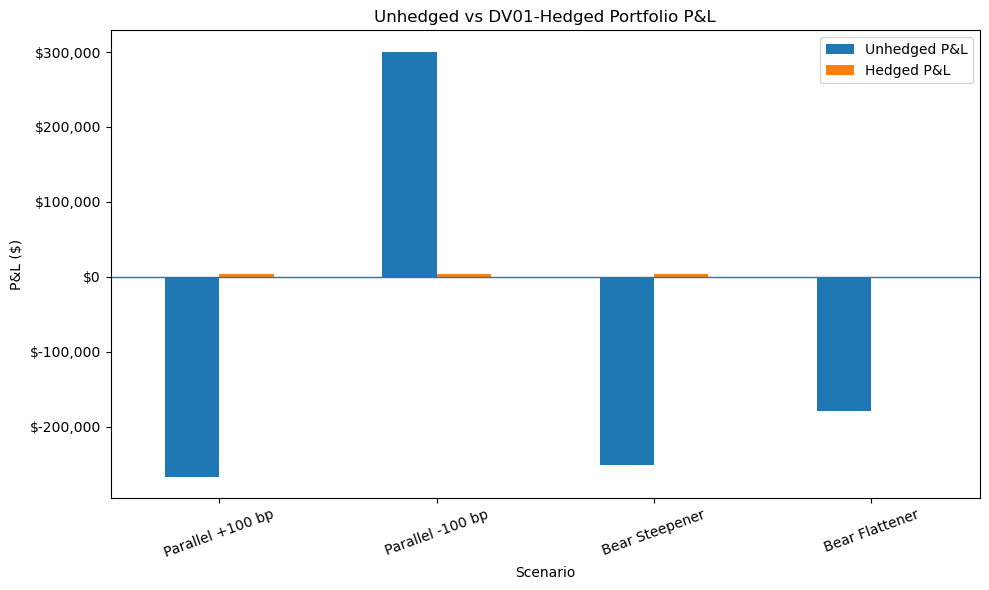

In [44]:
plot_data = (
    hedged_table
    .set_index("Scenario")[
        [
            "Unhedged P&L",
            "Hedged P&L"
        ]
    ]
)

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_title(
    "Unhedged vs DV01-Hedged Portfolio P&L"
)

ax.set_ylabel(
    "P&L ($)"
)

ax.set_xlabel(
    "Scenario"
)

ax.tick_params(
    axis="x",
    rotation=20
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"${x:,.0f}"
    )
)

plt.tight_layout()
plt.show()

### Hedge Effectiveness

The DV01-neutral hedge substantially reduces portfolio sensitivity to the tested interest-rate scenarios. A short position of approximately $3.47 million in the 10-year hedging bond offsets the portfolio's initial parallel-rate DV01.

Under a +100 bp parallel shift, the unhedged portfolio loses approximately $266,629, while the hedged portfolio records a residual gain of only about $3,282. Similarly, the large gain generated by a -100 bp shift is almost fully offset by the short hedge.

The hedge also performs strongly under the illustrative steepening and flattening scenarios. This result should not be interpreted as evidence that a single-duration hedge eliminates yield-curve risk generally. Its effectiveness depends on the particular portfolio, hedge instrument and scenario definitions used here.

DV01 matching neutralizes first-order exposure to a parallel rate movement but does not explicitly match maturity-specific key-rate exposures. A portfolio may therefore remain exposed to changes in curve slope and curvature even when its aggregate DV01 is close to zero.

## 12. Residual Key-Rate Risk After DV01 Hedging

Matching aggregate DV01 protects a portfolio primarily against small parallel movements in the yield curve. It does not ensure that interest-rate exposure is matched at individual maturities.

To examine this limitation, the unhedged portfolio and the DV01-neutral 10-year hedge are subjected to localized +100 bp shocks around the 2-year, 5-year, 10-year and 20-year key maturities.

These scenarios isolate different regions of the term structure and reveal residual curve risk that may remain hidden when only aggregate duration is considered.

In [45]:
key_rate_stress_curves = {}

for key_maturity in key_maturities:

    # Apply the same triangular key-rate shock
    # used for KRD, but scale it to +100 bp.
    node_shock = key_rate_shock(
        curve_data["Maturity"].values,
        key_maturity,
        shock_bps=100
    )

    stressed_yields = (
        curve_data["Yield"].values
        + node_shock
    )

    stressed_curve = interp1d(
        curve_data["Maturity"],
        stressed_yields,
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )

    key_rate_stress_curves[
        key_maturity
    ] = stressed_curve

In [46]:
for key_maturity, curve in key_rate_stress_curves.items():

    print(
        f"{key_maturity}Y shock:",
        np.round(
            (
                curve(curve_data["Maturity"])
                - curve_data["Yield"].values
            ) * 10_000,
            1
        )
    )

2Y shock: [ 25.  50. 100.  50.   0.   0.   0.   0.   0.]
5Y shock: [  0.    0.    0.   33.3 100.   33.3   0.    0.    0. ]
10Y shock: [  0.   0.   0.   0.   0.  40. 100.   0.   0.]
20Y shock: [  0.   0.   0.   0.   0.   0.   0. 100.   0.]


In [47]:
key_rate_hedge_results = []

base_hedge_value = bond_price_spot_curve(
    face_value=single_10y_hedge_notional,
    coupon_rate=hedge_bond["Coupon Rate"],
    maturity=hedge_bond["Maturity"],
    spot_curve=yield_curve,
    frequency=2
)

for key_maturity, stressed_curve in key_rate_stress_curves.items():

    # Unhedged portfolio
    stressed_portfolio_value = 0

    for _, bond in bond_portfolio.iterrows():

        stressed_portfolio_value += bond_price_spot_curve(
            face_value=bond["Face Value"],
            coupon_rate=bond["Coupon Rate"],
            maturity=bond["Maturity"],
            spot_curve=stressed_curve,
            frequency=2
        )

    unhedged_pnl = (
        stressed_portfolio_value
        - portfolio_market_value
    )

    # 10Y hedge
    stressed_hedge_value = bond_price_spot_curve(
        face_value=single_10y_hedge_notional,
        coupon_rate=hedge_bond["Coupon Rate"],
        maturity=hedge_bond["Maturity"],
        spot_curve=stressed_curve,
        frequency=2
    )

    hedge_pnl = -(
        stressed_hedge_value
        - base_hedge_value
    )

    hedged_pnl = (
        unhedged_pnl
        + hedge_pnl
    )

    key_rate_hedge_results.append({
        "Key Maturity": f"{key_maturity}Y",
        "Unhedged P&L": unhedged_pnl,
        "10Y Hedge P&L": hedge_pnl,
        "Hedged P&L": hedged_pnl
    })

key_rate_hedge_table = pd.DataFrame(
    key_rate_hedge_results
)

key_rate_hedge_table

,Key Maturity,Unhedged P&L,10Y Hedge P&L,Hedged P&L
0,2Y,"-24,402.355137","6,840.750972","-17,561.604165"
1,5Y,"-54,302.690724","21,200.589989","-33,102.100736"
2,10Y,"-92,017.860431","235,148.583300","143,130.722869"
3,20Y,"-92,011.239216",-0.000000,"-92,011.239216"


In [48]:
key_rate_hedge_table[
    "Risk Reduction"
] = (
    1
    - (
        key_rate_hedge_table["Hedged P&L"].abs()
        / key_rate_hedge_table["Unhedged P&L"].abs()
    )
)

key_rate_hedge_table

,Key Maturity,Unhedged P&L,10Y Hedge P&L,Hedged P&L,Risk Reduction
0,2Y,"-24,402.355137","6,840.750972","-17,561.604165",0.280332
1,5Y,"-54,302.690724","21,200.589989","-33,102.100736",0.390415
2,10Y,"-92,017.860431","235,148.583300","143,130.722869",-0.555467
3,20Y,"-92,011.239216",-0.000000,"-92,011.239216",0.000000


In [49]:
display_table = (
    key_rate_hedge_table.copy()
)

display_table["Unhedged P&L"] = (
    display_table["Unhedged P&L"]
    .map(lambda x: f"${x:,.0f}")
)

display_table["10Y Hedge P&L"] = (
    display_table["10Y Hedge P&L"]
    .map(lambda x: f"${x:,.0f}")
)

display_table["Hedged P&L"] = (
    display_table["Hedged P&L"]
    .map(lambda x: f"${x:,.0f}")
)

display_table["Risk Reduction"] = (
    display_table["Risk Reduction"]
    .map(lambda x: f"{x:.1%}")
)

display_table

,Key Maturity,Unhedged P&L,10Y Hedge P&L,Hedged P&L,Risk Reduction
0,2Y,"$-24,402","$6,841","$-17,562",28.0%
1,5Y,"$-54,303","$21,201","$-33,102",39.0%
2,10Y,"$-92,018","$235,149","$143,131",-55.5%
3,20Y,"$-92,011",$-0,"$-92,011",0.0%


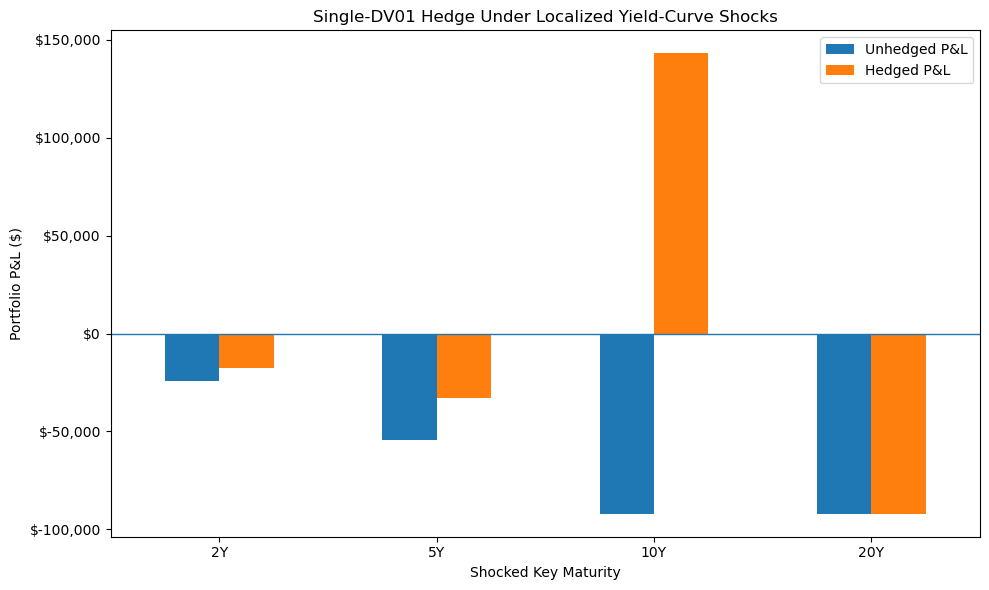

In [50]:
plot_data = (
    key_rate_hedge_table
    .set_index("Key Maturity")[
        [
            "Unhedged P&L",
            "Hedged P&L"
        ]
    ]
)

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_title(
    "Single-DV01 Hedge Under Localized Yield-Curve Shocks"
)

ax.set_xlabel(
    "Shocked Key Maturity"
)

ax.set_ylabel(
    "Portfolio P&L ($)"
)

ax.tick_params(
    axis="x",
    rotation=0
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"${x:,.0f}"
    )
)

plt.tight_layout()
plt.show()

### Residual Curve Risk After DV01 Hedging

The localized stress tests demonstrate an important limitation of aggregate DV01 hedging.

Although the short 10-year position substantially neutralizes the portfolio's exposure to parallel rate movements, it does not neutralize sensitivity at individual points along the yield curve.

Under localized 2-year and 5-year shocks, the hedge reduces losses by approximately 28% and 39%, respectively, but significant residual exposure remains. Under a localized 20-year shock, the 10-year hedge provides effectively no protection, leaving a portfolio loss of approximately $92,000.

The localized 10-year shock produces the opposite problem. Because the hedge position is concentrated at that maturity, it over-hedges the portfolio's 10-year exposure and transforms an approximately $92,000 unhedged loss into a $143,000 gain. The negative risk-reduction statistic reflects an increase in absolute P&L sensitivity rather than a reduction in risk.

This demonstrates that matching total portfolio DV01 is not equivalent to matching the portfolio's yield-curve exposure. A portfolio can be approximately neutral to parallel rate movements while retaining substantial exposure to changes in curve slope, curvature and individual maturity segments.

## 13. Multi-Instrument Key-Rate Hedging

A more robust hedge can be constructed by matching interest-rate sensitivity at multiple points along the yield curve.

Rather than neutralizing only aggregate DV01, a key-rate hedge uses several instruments with different maturities. The hedge notionals are selected so that their combined sensitivity offsets the portfolio's exposure to localized movements at the selected key maturities.

This converts the hedging problem into a system of linear equations:

$$
\mathbf{K}\mathbf{h} = -\mathbf{k}_P
$$

where $\mathbf{K}$ contains the key-rate dollar sensitivities of the hedge instruments, $\mathbf{h}$ contains the required hedge positions, and $\mathbf{k}_P$ represents the portfolio's key-rate dollar exposure.

The resulting hedge is designed to reduce sensitivity to changes in the shape of the yield curve rather than only to parallel shifts.

In [51]:
hedge_bonds = bond_portfolio.copy()

key_rate_dollar_matrix = []

for _, hedge in hedge_bonds.iterrows():

    instrument_sensitivities = []

    base_price = bond_price_spot_curve(
        face_value=1_000_000,
        coupon_rate=hedge["Coupon Rate"],
        maturity=hedge["Maturity"],
        spot_curve=yield_curve,
        frequency=2
    )

    for key_maturity in key_maturities:

        node_shock = key_rate_shock(
            curve_data["Maturity"].values,
            key_maturity,
            shock_bps=1
        )

        shocked_curve = interp1d(
            curve_data["Maturity"],
            curve_data["Yield"].values + node_shock,
            kind="linear",
            bounds_error=False,
            fill_value="extrapolate"
        )

        shocked_price = bond_price_spot_curve(
            face_value=1_000_000,
            coupon_rate=hedge["Coupon Rate"],
            maturity=hedge["Maturity"],
            spot_curve=shocked_curve,
            frequency=2
        )

        # Positive number = dollar loss for a +1 bp shock
        sensitivity = (
            base_price
            - shocked_price
        )

        instrument_sensitivities.append(
            sensitivity
        )

    key_rate_dollar_matrix.append(
        instrument_sensitivities
    )

K = np.array(
    key_rate_dollar_matrix
).T

K

array([[ 187.1419709 ,   17.66323374,   19.87113796,   22.07904217],
       [   0.        ,  425.03990057,   62.1193093 ,   69.02145477],
       [   0.        ,    0.        ,  711.04305451,  252.30591012],
       [   0.        ,    0.        ,    0.        , 1006.46516854]])

In [52]:
portfolio_key_rate_dv01 = (
    key_rate_table["Key-Rate Duration"].values
    * portfolio_market_value
    * 0.0001
)

portfolio_key_rate_dv01

array([ 246.75538477,  556.18066464,  963.34896463, 1006.46516854])

In [53]:
hedge_units = np.linalg.solve(
    K,
    -portfolio_key_rate_dv01
)

hedge_notionals = (
    hedge_units
    * 1_000_000
)

multi_hedge_table = pd.DataFrame({
    "Hedge Instrument": hedge_bonds["Bond"].values,
    "Hedge Notional": hedge_notionals
})

multi_hedge_table

,Hedge Instrument,Hedge Notional
0,2Y Note,"-1,000,000.000002"
1,5Y Note,"-1,000,000.000000"
2,10Y Note,"-1,000,000.000000"
3,20Y Bond,"-1,000,000.000000"


In [54]:
hedge_key_rate_dv01 = (
    K @ hedge_units
)

residual_key_rate_dv01 = (
    portfolio_key_rate_dv01
    + hedge_key_rate_dv01
)

hedge_verification = pd.DataFrame({
    "Key Maturity": [
        f"{int(x)}Y"
        for x in key_maturities
    ],
    "Portfolio DV01": portfolio_key_rate_dv01,
    "Hedge DV01": hedge_key_rate_dv01,
    "Residual DV01": residual_key_rate_dv01
})

hedge_verification

,Key Maturity,Portfolio DV01,Hedge DV01,Residual DV01
0,2Y,246.755385,-246.755385,0.000000
1,5Y,556.180665,-556.180665,0.000000
2,10Y,963.348965,-963.348965,0.000000
3,20Y,"1,006.465169","-1,006.465169",0.000000


### Unconstrained Key-Rate Hedge

The unconstrained key-rate system produces a mathematically exact solution: shorting $1 million face value of each 2-year, 5-year, 10-year and 20-year bond eliminates the portfolio's key-rate DV01 at every selected maturity.

This result is not economically meaningful as a hedging strategy because the hedge instruments are identical to the securities already held in the portfolio. The solution therefore amounts to fully offsetting, or effectively liquidating, every position.

The exercise nevertheless provides a useful benchmark. Exact matching of every key-rate exposure is possible when identical offsetting instruments are available, but practical hedging requires restrictions on the instruments and positions that can be used. A more realistic hedge should therefore reduce curve risk without simply replicating the negative of the existing portfolio.

## 14. Practical Constrained Key-Rate Hedge

In practice, a risk manager may not have access to an identical offsetting instrument for every portfolio position. Hedge construction therefore becomes an optimization problem rather than an exact replication problem.

A constrained hedge is constructed using only the 5-year and 10-year instruments. Because two hedge instruments cannot independently neutralize four key-rate exposures, the hedge notionals are estimated using least squares.

The objective is to minimize the portfolio's residual key-rate dollar sensitivity:

$$
\min_{\mathbf{h}}
\left\|
\mathbf{k}_P + \mathbf{K}_H\mathbf{h}
\right\|_2^2
$$

where $\mathbf{k}_P$ represents the portfolio's key-rate DV01 vector and $\mathbf{K}_H$ contains the key-rate sensitivities of the available hedge instruments.

This produces a practical compromise between aggregate risk reduction and residual yield-curve exposure.

In [55]:
practical_hedge_names = [
    "5Y Note",
    "10Y Note"
]

hedge_indices = [
    bond_portfolio.index[
        bond_portfolio["Bond"] == name
    ][0]
    for name in practical_hedge_names
]

K_practical = K[:, hedge_indices]

K_practical

array([[ 17.66323374,  19.87113796],
       [425.03990057,  62.1193093 ],
       [  0.        , 711.04305451],
       [  0.        ,   0.        ]])

In [56]:
practical_hedge_units, residuals, rank, singular_values = (
    np.linalg.lstsq(
        K_practical,
        -portfolio_key_rate_dv01,
        rcond=None
    )
)

practical_hedge_notionals = (
    practical_hedge_units
    * 1_000_000
)

practical_hedge_table = pd.DataFrame({
    "Hedge Instrument": practical_hedge_names,
    "Hedge Notional": practical_hedge_notionals
})

practical_hedge_table

,Hedge Instrument,Hedge Notional
0,5Y Note,"-1,129,060.540068"
1,10Y Note,"-1,361,670.261037"


In [57]:
practical_hedge_dv01 = (
    K_practical
    @ practical_hedge_units
)

practical_residual_dv01 = (
    portfolio_key_rate_dv01
    + practical_hedge_dv01
)

practical_verification = pd.DataFrame({
    "Key Maturity": [
        f"{int(x)}Y"
        for x in key_maturities
    ],
    "Portfolio DV01": portfolio_key_rate_dv01,
    "Hedge DV01": practical_hedge_dv01,
    "Residual DV01": practical_residual_dv01
})

practical_verification

,Key Maturity,Portfolio DV01,Hedge DV01,Residual DV01
0,2Y,246.755385,-47.000798,199.754587
1,5Y,556.180665,-564.481796,-8.301131
2,10Y,963.348965,-968.206182,-4.857217
3,20Y,"1,006.465169",0.000000,"1,006.465169"


In [58]:
initial_krd_risk = np.linalg.norm(
    portfolio_key_rate_dv01
)

residual_krd_risk = np.linalg.norm(
    practical_residual_dv01
)

krd_risk_reduction = (
    1
    - residual_krd_risk / initial_krd_risk
)

print(
    f"Initial KRD risk norm: "
    f"${initial_krd_risk:,.2f}"
)

print(
    f"Residual KRD risk norm: "
    f"${residual_krd_risk:,.2f}"
)

print(
    f"KRD risk reduction: "
    f"{krd_risk_reduction:.2%}"
)

Initial KRD risk norm: $1,520.28
Residual KRD risk norm: $1,026.14
KRD risk reduction: 32.50%


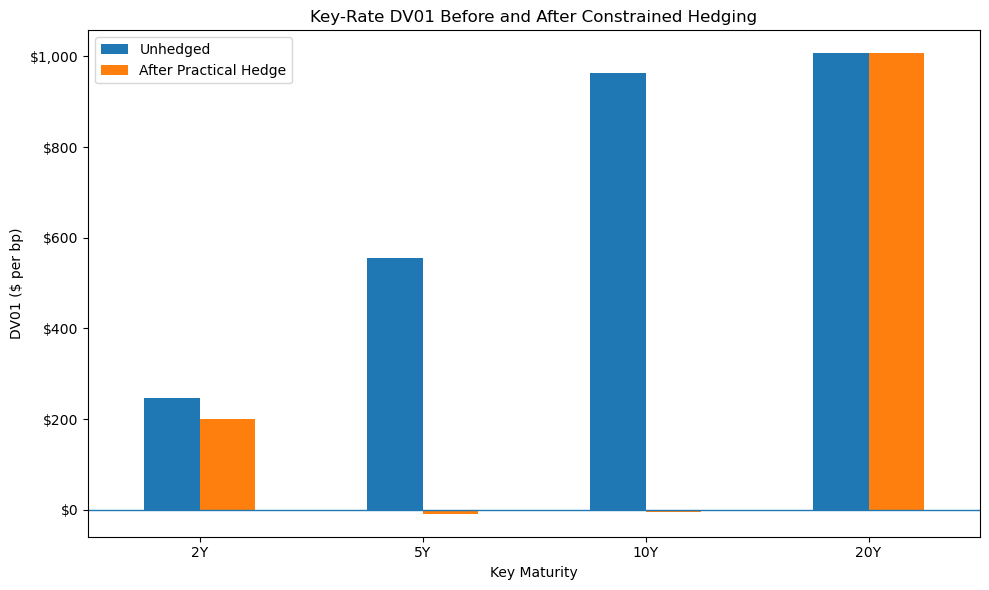

In [59]:
krd_comparison = pd.DataFrame({
    "Key Maturity": [
        f"{int(x)}Y"
        for x in key_maturities
    ],
    "Unhedged": portfolio_key_rate_dv01,
    "After Practical Hedge": practical_residual_dv01
})

ax = (
    krd_comparison
    .set_index("Key Maturity")
    .plot(
        kind="bar",
        figsize=(10, 6)
    )
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_title(
    "Key-Rate DV01 Before and After Constrained Hedging"
)

ax.set_xlabel(
    "Key Maturity"
)

ax.set_ylabel(
    "DV01 ($ per bp)"
)

ax.tick_params(
    axis="x",
    rotation=0
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"${x:,.0f}"
    )
)

plt.tight_layout()
plt.show()

### Constrained Hedge Interpretation

Restricting the available hedge instruments to the 5-year and 10-year bonds produces a more realistic hedging problem. The least-squares solution requires short positions of approximately $1.13 million and $1.36 million in the 5-year and 10-year instruments, respectively.

The hedge almost eliminates key-rate exposure around the 5-year and 10-year maturities. However, substantial residual exposure remains at the 2-year and particularly the 20-year key rates because the available hedge instruments cannot independently offset those parts of the curve.

The overall norm of the key-rate DV01 vector declines from approximately $1,520 to $1,026 per basis point, representing a 32.5% reduction in measured curve exposure.

This illustrates an important practical limitation of fixed-income hedging: hedge effectiveness depends not only on the amount of hedging capacity but also on whether the available instruments span the maturity-specific risks embedded in the portfolio.

## 15. Constrained Hedge Stress Testing

The constrained key-rate hedge is now evaluated under the same parallel and non-parallel yield-curve scenarios used earlier.

This provides an out-of-sample-style comparison between three portfolio configurations:

1. the original unhedged portfolio,
2. the single-instrument 10-year DV01 hedge,
3. the constrained 5-year/10-year key-rate hedge.

The objective is not necessarily to eliminate P&L under every scenario, but to determine how different hedge constructions alter the portfolio's exposure to changes in the level and shape of the yield curve.

In [60]:
practical_stress_results = []

for scenario, shocked_curve in scenario_curves.items():

    # Original portfolio P&L
    shocked_portfolio_value = 0

    for _, bond in bond_portfolio.iterrows():

        shocked_portfolio_value += bond_price_spot_curve(
            face_value=bond["Face Value"],
            coupon_rate=bond["Coupon Rate"],
            maturity=bond["Maturity"],
            spot_curve=shocked_curve,
            frequency=2
        )

    portfolio_pnl = (
        shocked_portfolio_value
        - portfolio_market_value
    )

    # Constrained hedge P&L
    practical_hedge_pnl = 0

    for hedge_name, practical_notional in zip(
        practical_hedge_names,
        practical_hedge_notionals
    ):

        hedge = bond_portfolio.loc[
            bond_portfolio["Bond"] == hedge_name
        ].iloc[0]

        base_value = bond_price_spot_curve(
            face_value=abs(practical_notional),
            coupon_rate=hedge["Coupon Rate"],
            maturity=hedge["Maturity"],
            spot_curve=yield_curve,
            frequency=2
        )

        shocked_value = bond_price_spot_curve(
            face_value=abs(practical_notional),
            coupon_rate=hedge["Coupon Rate"],
            maturity=hedge["Maturity"],
            spot_curve=shocked_curve,
            frequency=2
        )

        position_sign = np.sign(
            practical_notional
        )

        practical_hedge_pnl += (
            position_sign
            * (shocked_value - base_value)
        )

    constrained_pnl = (
        portfolio_pnl
        + practical_hedge_pnl
    )

    practical_stress_results.append({
        "Scenario": scenario,
        "Unhedged P&L": portfolio_pnl,
        "Constrained Hedge P&L": practical_hedge_pnl,
        "Constrained Portfolio P&L": constrained_pnl
    })

practical_stress_table = pd.DataFrame(
    practical_stress_results
)

practical_stress_table

,Scenario,Unhedged P&L,Constrained Hedge P&L,Constrained Portfolio P&L
0,Parallel +100 bp,"-266,629.040211","155,149.674445","-111,479.365766"
1,Parallel -100 bp,"300,627.920610","-168,414.867034","132,213.053576"
2,Bear Steepener,"-251,540.457871","132,010.992648","-119,529.465223"
3,Bear Flattener,"-179,107.177149","115,150.580810","-63,956.596340"


In [61]:
hedge_comparison = (
    hedged_table[
        [
            "Scenario",
            "Unhedged P&L",
            "Hedged P&L"
        ]
    ]
    .rename(
        columns={
            "Hedged P&L":
            "Single 10Y DV01 Hedge"
        }
    )
    .merge(
        practical_stress_table[
            [
                "Scenario",
                "Constrained Portfolio P&L"
            ]
        ],
        on="Scenario"
    )
)

hedge_comparison

,Scenario,Unhedged P&L,Single 10Y DV01 Hedge,Constrained Portfolio P&L
0,Parallel +100 bp,"-266,629.040211","3,281.591382","-111,479.365766"
1,Parallel -100 bp,"300,627.920610","3,643.974706","132,213.053576"
2,Bear Steepener,"-251,540.457871","4,286.195321","-119,529.465223"
3,Bear Flattener,"-179,107.177149","-1,189.301647","-63,956.596340"


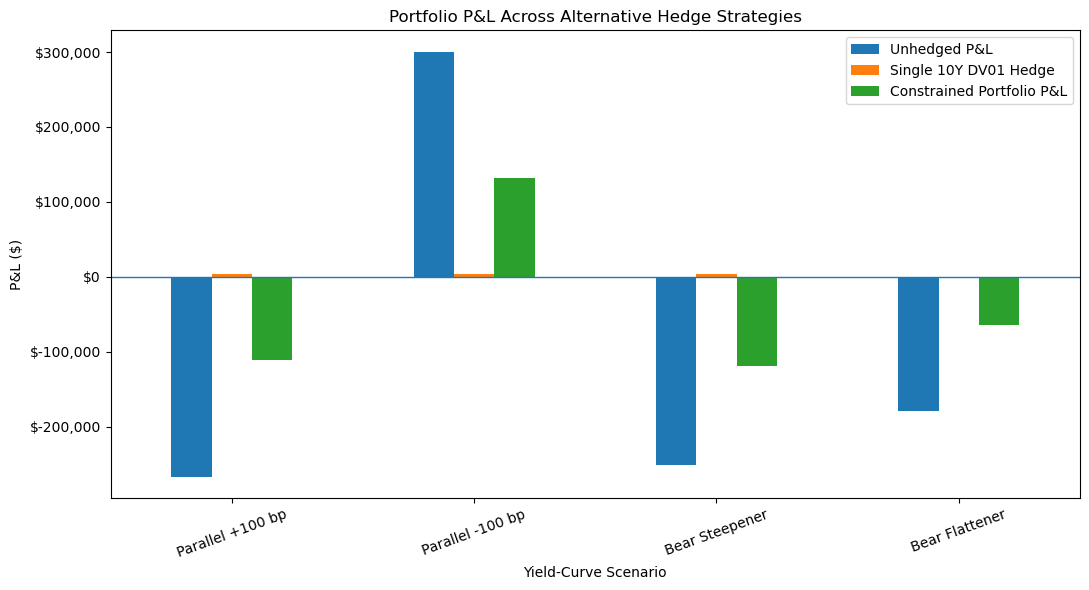

In [62]:
plot_data = (
    hedge_comparison
    .set_index("Scenario")
)

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.axhline(
    0,
    linewidth=1
)

ax.set_title(
    "Portfolio P&L Across Alternative Hedge Strategies"
)

ax.set_xlabel(
    "Yield-Curve Scenario"
)

ax.set_ylabel(
    "P&L ($)"
)

ax.tick_params(
    axis="x",
    rotation=20
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"${x:,.0f}"
    )
)

plt.tight_layout()
plt.show()

In [63]:
stress_summary = hedge_comparison.copy()

stress_summary[
    "Single-Hedge Risk Reduction"
] = (
    1
    - (
        stress_summary[
            "Single 10Y DV01 Hedge"
        ].abs()
        / stress_summary[
            "Unhedged P&L"
        ].abs()
    )
)

stress_summary[
    "Constrained-Hedge Risk Reduction"
] = (
    1
    - (
        stress_summary[
            "Constrained Portfolio P&L"
        ].abs()
        / stress_summary[
            "Unhedged P&L"
        ].abs()
    )
)

stress_summary

,Scenario,Unhedged P&L,Single 10Y DV01 Hedge,Constrained Portfolio P&L,Single-Hedge Risk Reduction,Constrained-Hedge Risk Reduction
0,Parallel +100 bp,"-266,629.040211","3,281.591382","-111,479.365766",0.987692,0.581893
1,Parallel -100 bp,"300,627.920610","3,643.974706","132,213.053576",0.987879,0.560210
2,Bear Steepener,"-251,540.457871","4,286.195321","-119,529.465223",0.982960,0.524810
3,Bear Flattener,"-179,107.177149","-1,189.301647","-63,956.596340",0.993360,0.642914


### Hedge Strategy Comparison

The stress results demonstrate an important distinction between aggregate duration hedging and key-rate hedging.

The single 10-year DV01 hedge performs extremely well under the selected broad yield-curve scenarios, reducing absolute portfolio P&L by approximately 98–99%. This occurs because the hedge was calibrated to offset the portfolio's aggregate first-order interest-rate sensitivity, while the stress scenarios contain substantial common movements across maturities.

The constrained 5-year/10-year key-rate hedge provides less protection under these broad scenarios, reducing absolute P&L by approximately 52–64%. Its objective is different: rather than targeting aggregate DV01 alone, it attempts to reduce the distribution of interest-rate exposure across selected points of the yield curve.

The earlier localized-shock analysis shows why this distinction matters. A portfolio can be approximately DV01-neutral while retaining substantial exposure to changes in yield-curve shape. In particular, the single 10-year hedge can over-hedge some localized movements while leaving other maturity exposures largely unprotected.

Therefore, hedge effectiveness is conditional on the underlying risk factor. Aggregate DV01 hedging can be highly effective against level shifts, while key-rate analysis is required to identify and manage exposure to non-parallel movements in the yield curve.

In [64]:
single_hedge_gross_notional = abs(
    single_10y_hedge_notional
)

constrained_gross_notional = np.sum(
    np.abs(practical_hedge_notionals)
)

hedge_efficiency = pd.DataFrame({
    "Strategy": [
        "Single 10Y DV01 Hedge",
        "Constrained 5Y/10Y Hedge"
    ],
    "Gross Hedge Notional": [
        single_hedge_gross_notional,
        constrained_gross_notional
    ],
    "Gross Notional / Portfolio Value": [
        single_hedge_gross_notional
        / portfolio_market_value,

        constrained_gross_notional
        / portfolio_market_value
    ]
})

hedge_efficiency

,Strategy,Gross Hedge Notional,Gross Notional / Portfolio Value
0,Single 10Y DV01 Hedge,"3,471,746.566305",0.850296
1,Constrained 5Y/10Y Hedge,"2,490,730.801105",0.610027


### Hedge Notional and Implementation Trade-off

The single 10-year DV01 hedge uses approximately $3.47 million of gross notional, or about 85% of the portfolio's market value. The constrained 5-year/10-year hedge uses approximately $2.49 million, or about 61% of portfolio value.

The comparison highlights an implementation trade-off. The single-instrument hedge is highly effective against the broad scenarios tested here, but requires materially more gross positioning and remains vulnerable to localized curve movements. The constrained hedge uses less gross notional and targets maturity-specific exposure, but leaves meaningful residual risk—especially at the 20-year key rate, where no hedge instrument is available.

Overall, the analysis shows that no single hedge metric is sufficient: aggregate DV01, key-rate exposure, scenario P&L and hedge notional should be considered jointly when evaluating an interest-rate hedging strategy.
